# Bab 12 — Neural networks that write like Shakespeare: recurrent layers for variable-length data

**Mahasiswa:** Tarannia Raisha Putri · 101032300231 · TK4702 · Deep Learning

**Referensi utama:** Andrew W. Trask, *Grokking Deep Learning*, Manning (2019), Bab 12, halaman cetak 209–229 (PDF 230–250, indeks PDF mulai 1). Subbab spesifik dicantumkan pada setiap tahap.

**Tujuan pembelajaran:** Membuktikan invariansi bag-of-words, menelusuri recurrent state, dan menguji gradien BPTT.

## Ringkasan

Rata-rata vektor kata berguna untuk kemiripan kalimat tetapi kehilangan urutan. Buku memperkenalkan transition matrix, recurrent state, forward sepanjang sekuens, serta backpropagation through time pada corpus bAbI. Judul menyebut Shakespeare, tetapi contoh pelatihan bab ini adalah bAbI; Shakespeare baru dipakai Bab 14.

## Konsep, intuisi, dan notasi

Sebelum membaca token $s_t$, state $h_t\in\mathbb R^H$ memprediksi $p_t=\operatorname{softmax}(h_tD)$, lalu diperbarui $h_{t+1}=h_tR+E_{s_t}$. $E:(V,H)$, $R:(H,H)$, $D:(H,V)$, $h_0:(H,)$. Dengan $R=I$, state adalah penjumlahan embedding; R yang dilatih dapat membedakan posisi.

Loss $L=-\frac1T\sum_t\log p_t[s_t]$, perplexity $\exp(L)$. Jika $g_{t+1}=\partial L/\partial h_{t+1}$, maka $G_E[s_t]\mathrel{+}=g_{t+1}$, $G_R\mathrel{+}=h_t^Tg_{t+1}$, $g_t=(p_t-y_t)D^T/T+g_{t+1}R^T$. Kontribusi decoder $G_D\mathrel{+}=h_t^T(p_t-y_t)/T$.

Indeks waktu penting: token terakhir yang baru dimasukkan setelah prediksi terakhir belum memengaruhi loss berikutnya. Gradien embedding token tersebut dari penggunaan terakhir adalah nol. Ini menjadi pemeriksaan kuat terhadap salah geser BPTT.

## Persiapan dan cara membaca

Jalankan **Restart Kernel → Run All**. Semua penjelasan merupakan parafrasa orisinal; angka hasil berada pada output sel yang benar-benar dijalankan. Label **reproduksi** berarti algoritme/contoh buku ditulis ulang; **koreksi/penyesuaian** menunjukkan perubahan; **tambahan** menunjukkan eksperimen atau interpretasi praktikum. `GDL_MODE=quick` mengurangi latihan berat; `full` memilih anggaran buku, dengan perubahan yang tetap dicatat. Keberhasilan eksekusi tidak membuktikan kesamaan akurasi dengan buku.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Jalankan dari root repository atau notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
MODE = os.environ.get('GDL_MODE', 'quick')
assert MODE in {'quick', 'full'}
FULL = MODE == 'full'
np.random.seed(1)
np.set_printoptions(precision=6, suppress=True)
METRICS = {}
def record(**values):
    METRICS.update(values)
def finite(*arrays):
    assert all(np.isfinite(np.asarray(a)).all() for a in arrays), 'NaN/inf terdeteksi'
def softmax(z):
    z = np.asarray(z)
    e = np.exp(z - np.max(z, axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)
def sigmoid(z):
    return np.exp(-np.logaddexp(0, -np.asarray(z)))
print('Mode:', MODE, '| NumPy:', np.__version__)

Mode: quick | NumPy: 2.5.4


<a id="b12-average"></a>

## Reproduksi: averaged embeddings dan keterbatasan bag-of-words

**Sumber:** cetak 210–215; PDF 231–236.

Notebook pendamping memakai `weights_0_1` dari bab sebelumnya tanpa membangunnya. Agar kernel bersih, kita melatih ulang CBOW dari IMDB di sini. Mode ringan memakai subset asli yang sama seperti Bab 11; embedding tidak diklaim sudah terlatih penuh. Normalisasi L2 adalah koreksi terhadap perkalian squared norm pada listing. Retrieval hanya demonstrasi tanpa target evaluasi.

In [2]:
def train_cbow(raw_reviews, full=False, corrected=True):
    import random
    rng=np.random.RandomState(1)
    tokens=[line.split() for line in raw_reviews]
    vocabulary=sorted({word for sent in tokens for word in sent})
    lookup={word:i for i,word in enumerate(vocabulary)}
    sequences=[[lookup[w] for w in sent] for sent in tokens]
    concatenated=np.array([i for sent in sequences for i in sent])
    random.Random(1).shuffle(sequences)
    selected=sequences if full else [sent[:80] for sent in sequences[:200]]
    E=(rng.rand(len(vocabulary),50)-.5)*.2; O=np.zeros_like(E)
    target=np.array([1.,0.,0.,0.,0.,0.]); losses=[]; updates=0
    for epoch in range(2):
        total=0.; count=0
        for sequence in selected:
            for t,word in enumerate(sequence):
                end=t+3 if corrected else t+2
                context=sequence[max(0,t-2):t]+sequence[t+1:min(len(sequence),end)]
                if not context: continue
                samples=[word]+concatenated[(rng.rand(5)*len(concatenated)).astype(int)].tolist()
                h=E[context].mean(0); logits=h@O[samples].T; p=sigmoid(logits)
                total+=np.sum(np.logaddexp(0,logits)-target*logits); count+=6
                d=p-target; dh=d@O[samples]; dO=np.outer(d,h)
                if corrected:
                    np.add.at(E,context,-.05*np.broadcast_to(dh/len(context),(len(context),50)))
                    np.add.at(O,samples,-.05*dO)
                else:
                    E[context]-=.05*dh
                    O[samples]-=.05*dO
                updates+=1
        losses.append(total/count)
    finite(E,O,losses)
    return E,O,vocabulary,lookup,losses,updates

def nearest(E,vocabulary,lookup,word,k=6):
    if word not in lookup: return [('OOV: '+word,0.)]
    distances=np.linalg.norm(E-E[lookup[word]],axis=1)
    return [(vocabulary[i],float(distances[i])) for i in np.argsort(distances)[:k]]

In [3]:
from src.datasets import reviews,babi
raw_reviews,_=reviews()
E,_,vocabulary,w2i,_,_=train_cbow(raw_reviews,FULL,True)
En=E/np.maximum(np.linalg.norm(E,axis=1,keepdims=True),1e-12)
def sentence_vector(words):
    ids=[w2i[w] for w in words if w in w2i]
    return En[ids].mean(0) if ids else np.zeros(En.shape[1])
review_vectors=np.array([sentence_vector(sorted(set(line.split()))) for line in raw_reviews[:1000]])
query=sentence_vector(['boring','awful'])
scores=review_vectors@query
print('Tiga indeks review terdekat:',scores.argsort()[-3:][::-1])
np.testing.assert_allclose(sentence_vector(['cat','dog']),sentence_vector(['dog','cat']))
print('Menukar urutan kata tidak mengubah rata-rata embedding.')

Tiga indeks review terdekat: [439 772 883]
Menukar urutan kata tidak mengubah rata-rata embedding.


<a id="b12-identity"></a>

## Reproduksi: identity, transition, toy forward dan backward

**Sumber:** cetak 216–221; PDF 237–242.

Contoh vektor `this`, `movie`, `rocks` dan sembilan kata tim olahraga mengikuti halaman 217 dan 220. PDF mengeja `sox`, sedangkan upstream `socks`; notebook memilih `sox` sesuai PDF. State yang dipakai menghitung gradien disalin sebelum update supaya tidak berubah karena alias array.

In [4]:
I=np.eye(3); this=np.array([2,4,6]); movie=np.array([10,10,10]); rocks=np.array([1,1,1])
print('Identitas:',I,'penjumlahan:',this+movie+rocks)
np.testing.assert_allclose((this@I+movie)@I+rocks,this+movie+rocks)
words=['yankees','bears','braves','red','sox','lose','defeat','beat','tie']
vectors={w:np.zeros((1,3)) for w in words}; decoder=np.random.RandomState(1).rand(3,9); transition=np.eye(3)
l0=vectors['red'].copy(); l1=l0@transition+vectors['sox']; l2=l1@transition+vectors['defeat']
p=softmax(l2@decoder); print('Prediksi awal:',p)
target=np.eye(9)[0:1]; dp=p-target; d2=dp@decoder.T; d1=d2@transition.T; d0=d1@transition.T
Gdecoder=l2.T@dp; Gtransition=l0.T@d1+l1.T@d2
for word,g in [('red',d0),('sox',d1),('defeat',d2)]: vectors[word]-=.01*g
transition-=.01*Gtransition; decoder-=.01*Gdecoder
print('Embedding red setelah satu update:',vectors['red'])

Identitas: [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]] penjumlahan: [13 15 17]
Prediksi awal: [[0.111111 0.111111 0.111111 0.111111 0.111111 0.111111 0.111111 0.111111
  0.111111]]
Embedding red setelah satu update: [[ 0.001273  0.0005   -0.004118]]


<a id="b12-babi"></a>

## Reproduksi: setup bAbI dan arbitrary-length forward

**Sumber:** cetak 222–224; PDF 243–245.

bAbI memang corpus sintetis asli yang dipilih buku, bukan pengganti buatan praktikum. Gunakan 1.000 baris pertama training resmi; ID baris dibuang, tanda baca/tab dipertahankan sesuai listing literal. Loop buku membuang token pertama lagi (`[1:]`); cabang listing mempertahankan perilaku tersebut, sedangkan koreksi memakai kalimat lengkap. Urutan vocabulary diurutkan agar reproducible.

In [5]:
tokens=babi('train',1000); vocabulary=sorted({w for s in tokens for w in s}); w2i={w:i for i,w in enumerate(vocabulary)}
sequences=[[w2i[w] for w in s] for s in tokens]
rng=np.random.RandomState(1); H=10; V=len(vocabulary)
initial=[(rng.rand(V,H)-.5)*.1,np.eye(H),np.zeros(H),(rng.rand(H,V)-.5)*.1]
def forward_sequence(sequence,parameters):
    E,R,start,D=parameters; states=[start.copy()]; probabilities=[]; losses=[]
    for token in sequence:
        p=softmax(states[-1]@D); probabilities.append(p); losses.append(-np.log(max(p[token],1e-300)))
        states.append(states[-1]@R+E[token])
    return np.array(states),np.array(probabilities),float(np.mean(losses))
print('Contoh token asli:',tokens[:3]); print('Vocab:',V,'shapes:',[p.shape for p in initial])

Contoh token asli: [['mary', 'moved', 'to', 'the', 'bathroom.'], ['john', 'went', 'to', 'the', 'hallway.'], ['where', 'is', 'mary?', '\tbathroom\t1']]
Vocab: 82 shapes: [(82, 10), (10, 10), (10,), (10, 82)]


<a id="b12-bptt"></a>

## Reproduksi dan koreksi: BPTT, update, dan analisis

**Sumber:** cetak 225–229; PDF 246–250.

Fungsi backward dapat memilih indeks literal buku atau indeks yang sesuai persamaan forward. Semua gradien dikumpulkan sebelum parameter diubah. Penyesuaian ini penting karena listing mengaitkan beberapa `hidden_delta` dengan embedding/transisi yang bergeser satu langkah. Perbandingan central difference di bawah menguji kekeliruan tersebut secara langsung.

Gradient check koreksi: 5.723728025558688e-10 listing: 0.008199325645121078


listing perplexity observasi terakhir: [700.        81.917814]
koreksi perplexity observasi terakhir: [700.        81.990871]


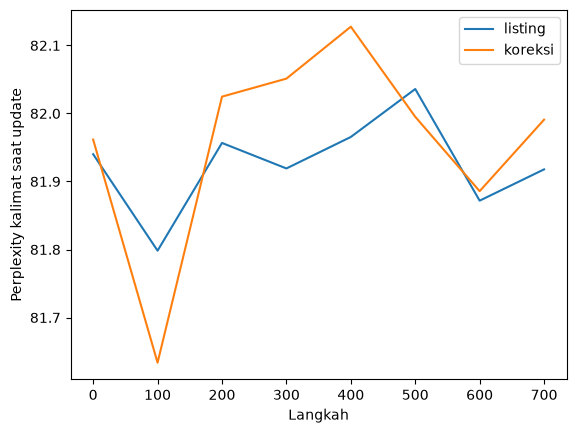

Test perplexity: 81.90779427392404 token dinilai: 4781 OOV diabaikan: 5
Prefix: [] target: sandra prediksi: 	kitchen	13
Prefix: ['sandra'] target: moved prediksi: 	hallway	8
Prefix: ['sandra', 'moved'] target: to prediksi: 	hallway	8
Prefix: ['sandra', 'moved', 'to'] target: the prediksi: 	hallway	8
Prefix: ['sandra', 'moved', 'to', 'the'] target: garden. prediksi: 	hallway	8


In [6]:
def sequence_gradients(sequence,parameters,book=False):
    E,R,start,D=parameters
    states,probs,loss=forward_sequence(sequence,parameters)
    T=len(sequence); dy=probs.copy(); dy[np.arange(T),sequence]-=1
    q=np.zeros((T,H))
    for t in reversed(range(T)):
        q[t]=dy[t]@D.T+(q[t+1]@R.T if t+1<T else 0)
    GE=np.zeros_like(E); GR=np.zeros_like(R); GD=states[:-1].T@dy
    for t,token in enumerate(sequence):
        if book:
            GE[token]+=q[t-1] if t else q[0]@R.T
            GR+=np.outer(states[t],q[t])
        elif t+1<T:
            GE[token]+=q[t+1]; GR+=np.outer(states[t],q[t+1])
    Gstart=q[0]@R.T if book else q[0]
    return loss,[g/T for g in [GE,GR,Gstart,GD]]
# Tambahan finite difference: gunakan transisi nonidentitas agar pergeseran indeks terlihat.
check=[p.copy() for p in initial]; check[1]*=.9
sentence=sequences[0]; _,G=sequence_gradients(sentence,check); _,Gbook=sequence_gradients(sentence,check,True)
eps=1e-6; errors=[]; book_errors=[]
for k,P in enumerate(check):
    indices=list(np.ndindex(P.shape))[:12]
    if k==0: indices=[(sentence[0],j) for j in range(H)]
    for idx in indices:
        old=P[idx]; P[idx]=old+eps; plus=forward_sequence(sentence,check)[2]
        P[idx]=old-eps; minus=forward_sequence(sentence,check)[2]; P[idx]=old
        numeric=(plus-minus)/(2*eps)
        errors.append(abs(numeric-G[k][idx])); book_errors.append(abs(numeric-Gbook[k][idx]))
assert max(errors)<1e-7
print('Gradient check koreksi:',max(errors),'listing:',max(book_errors))
def fit_rnn(book=False):
    parameters=[p.copy() for p in initial]; history=[]; steps=30000 if FULL else 800
    for step in range(steps):
        sent=sequences[step%len(sequences)]
        if book: sent=sent[1:]
        loss,grads=sequence_gradients(sent,parameters,book)
        for P,G in zip(parameters,grads): P-=.001*G
        if step%100==0: history.append([step,np.exp(loss)])
    finite(*parameters,history)
    return parameters,np.array(history)
book_model,book_history=fit_rnn(True); model,history=fit_rnn(False)
for name,hist in [('listing',book_history),('koreksi',history)]:
    print(name,'perplexity observasi terakhir:',hist[-1]); plt.plot(hist[:,0],hist[:,1],label=name)
plt.xlabel('Langkah'); plt.ylabel('Perplexity kalimat saat update'); plt.legend(); plt.show()
# Tambahan evaluasi file test resmi; kata OOV diabaikan dan jumlahnya dilaporkan.
test_tokens=babi('test',1000); nll=0.; count=0; oov=0
for sentence in test_tokens:
    ids=[w2i[w] for w in sentence if w in w2i]; oov+=sum(w not in w2i for w in sentence)
    if ids:
        _,_,loss=forward_sequence(ids,model); nll+=loss*len(ids); count+=len(ids)
test_ppl=float(np.exp(nll/count))
print('Test perplexity:',test_ppl,'token dinilai:',count,'OOV diabaikan:',oov)
sentence=sequences[4]; states,probs,_=forward_sequence(sentence,model)
for t in range(len(sentence)):
    print('Prefix:',[vocabulary[i] for i in sentence[:t]],'target:',vocabulary[sentence[t]],'prediksi:',vocabulary[probs[t].argmax()])
record(steps=30000 if FULL else 800,gradient_max_error=float(max(errors)),book_gradient_max_error=float(max(book_errors)),test_perplexity=test_ppl,test_oov=oov)

## Analisis output aktual — run tersimpan

Mode **quick**, eksekusi 2026-10-16T01:51:05.675021+07:00. Ringkasan ini dibuat dari output validator, bukan angka contoh dalam buku.

Gradien BPTT koreksi memiliki galat 5.724e-10; indeks listing 8.199e-03. Setelah 800 update, test perplexity 81.908 dengan 5 token OOV diabaikan. Angka masih tinggi; latihan singkat belum mempelajari pola bahasa dengan baik.

## Kesimpulan dan pembahasan pertanyaan

Recurrent state memungkinkan urutan memengaruhi prediksi. Gradient check menunjukkan mengapa indeks waktu perlu diperiksa meskipun program dapat berjalan. Perplexity adalah eksponensial NLL rata-rata, bukan persentase akurasi; test bAbI yang dihitung di sini bukan evaluasi QA.

**Mengapa matriks identitas menghilangkan urutan?** Ia membuat state hanya jumlah embedding, yang komutatif.

**Mengapa kata terakhir tidak mengubah loss terakhir pada forward ini?** Prediksi dibuat sebelum kata itu dimasukkan ke state.

**Mengapa bAbI tidak bisa diprediksi sempurna dari satu prefix?** Prefix seperti “moved to the” dapat diikuti banyak lokasi; informasi belum cukup.

In [7]:
finite(*[v for v in METRICS.values() if isinstance(v, (int, float))])
print('VALIDATION_METRICS=' + json.dumps(METRICS, sort_keys=True))

VALIDATION_METRICS={"book_gradient_max_error": 0.008199325645121078, "gradient_max_error": 5.723728025558688e-10, "steps": 800, "test_oov": 5, "test_perplexity": 81.90779427392404}
